# Notebook 16 — E4 opponent-routing gate ablation

**Question.** How should opponent-directed routing be gated relative to remaining economic opportunities?

**Additional framing.** When economic objectives remain or are unreachable, when is it worthwhile to direct safe actions towards an opponent? This experiment tests whether fallback opponent routing improves offensive conversion and whether a strict hunt-only gate better protects remaining economic opportunities.

## Locked experimental design

- Frozen candidate: `dueling_hunt_center_04`; checkpoint `709cca4351f3bc5893f766b01b8c9335fa299d25331a275ae281b123df31009a`
- Conditions: `opponent_route_off`, `fallback_final`, `strict_hunt_only`
- Main lineups: `external_mixed` and `frozen_dddqn`
- Added robustness lineups: `rule3` and `internal_mixed`
- Fresh seeds: `68001–68040`; 5 rounds per seed
- Workload: 2,400 rounds; no training and zero exploration
- Primary metric: mean score per round
- Prespecified contrasts: fallback − off, strict − fallback, strict − off
- Inference: average five rounds within seed, then paired 10,000-replicate seed-cluster bootstrap

The manipulation is source-selective: only an `objective_target` produced by the `opponent` source is cleared, before both network inference and the +1.0 direct Q bonus. The 6-step safety layer, hybrid bomb rule, economic/escape routes, +0.04 centre bias, 0.60 revisit penalty, architecture, weights, and learned opponent features are fixed.

In [1]:
from pathlib import Path
import json, pandas as pd
ROOT = Path('..').resolve()
main_payload = json.loads((ROOT/'results/e4_opponent_routing_gate/summary.json').read_text())
extension_payload = json.loads((ROOT/'results/e4_opponent_routing_gate_extension/summary.json').read_text())
aggregate = pd.DataFrame(main_payload['aggregate'] + extension_payload['aggregate'])
paired = pd.DataFrame(main_payload['paired_bootstrap'] + extension_payload['paired_bootstrap'])
aggregate

,lineup,variant,seed_clusters,rounds,score,coins,crates,bombs,kills,suicides,...,hunt_round,self_trapped_after_bomb,decision_ms_mean,opponent_route_opportunity_rate,opponent_route_enabled_rate,opponent_target_selection_rate,coin_routing_activation_rate,opponent_with_coin_rate,nonzero_trap_pressure_bomb_rate,decision_ms_p95
0,external_mixed,opponent_route_off,40,200,2.570,1.770,23.840,41.385,0.160,0.190,...,0.740,0.215,6.055256,0.185742,0.000000,0.325715,0.060409,0.000243,0.652410,15.511394
1,external_mixed,fallback_final,40,200,2.645,1.770,23.840,41.435,0.175,0.145,...,0.740,0.175,7.788007,0.179283,0.179283,0.678527,0.059841,0.000249,0.733438,19.862795
2,external_mixed,strict_hunt_only,40,200,2.645,1.770,23.840,41.345,0.175,0.140,...,0.740,0.165,7.575750,0.178750,0.178705,0.678363,0.059927,0.000251,0.732979,19.205666
3,frozen_dddqn,opponent_route_off,40,200,3.135,2.210,27.660,40.130,0.185,0.330,...,0.875,0.445,7.080984,0.191228,0.000000,0.387923,0.069863,0.000000,0.678046,18.755913
4,frozen_dddqn,fallback_final,40,200,3.485,2.210,27.660,40.830,0.255,0.245,...,0.875,0.305,7.294643,0.186758,0.186758,0.714384,0.067223,0.000000,0.730100,19.151926
5,frozen_dddqn,strict_hunt_only,40,200,3.485,2.210,27.660,40.830,0.255,0.245,...,0.875,0.305,7.120692,0.186758,0.186758,0.714384,0.067223,0.000000,0.730100,18.644810
6,rule3,opponent_route_off,40,200,4.020,2.995,29.980,41.180,0.205,0.235,...,0.675,0.225,4.960452,0.130725,0.000000,0.315379,0.101601,0.000458,0.522098,13.509035
7,rule3,fallback_final,40,200,4.145,2.995,29.980,41.405,0.230,0.165,...,0.675,0.160,5.292813,0.126388,0.126388,0.714252,0.100151,0.000350,0.606086,14.342844
8,rule3,strict_hunt_only,40,200,4.145,2.995,29.980,41.395,0.230,0.165,...,0.675,0.160,5.627503,0.126624,0.126565,0.714202,0.100136,0.000466,0.606474,15.184212
9,internal_mixed,opponent_route_off,40,200,3.045,2.245,30.185,47.185,0.160,0.185,...,0.935,0.270,6.138957,0.225029,0.000000,0.386373,0.062698,0.000177,0.606655,16.035557


## Completeness and matched initial conditions

| lineup | matched_rounds | expected |
| --- | --- | --- |
| external_mixed | 200 | 200 |
| frozen_dddqn | 200 | 200 |
| rule3 | 200 | 200 |
| internal_mixed | 200 | 200 |

## Metric definitions

- `opponent_route_opportunity_rate`: counterfactual opponent objectives divided by all candidate decisions. It is measured before the arm-specific gate.
- `opponent_route_enabled_rate`: enabled opponent objectives divided by all decisions.
- `opponent_target_selection_rate`: among opponent-route opportunities, fraction whose ultimately selected action was in the counterfactual target set.
- `opponent_progress`: chosen-action BFS progress toward an opponent-adjacent tile, conditional on an opponent-route opportunity.
- `trap_pressure_bombs`: selected bombs with positive simulated reduction in opponents' safe reachable positions.
- `nonzero_trap_pressure_bomb_rate`: those bombs divided by all selected bombs.
- `bomb_opponent_yield`: summed normalized direct opponent blast coverage per round.
- `opponent_with_coin_rate`: opponent-route opportunities occurring while at least one coin remained, divided by all opponent-route opportunities.
- `hunt_round`: fraction of rounds containing at least one true hunt-phase step.
- `self_trapped_after_bomb`: placed candidate bombs after which no viable safe continuation remained while that bomb was active.

## Aggregate results

All count metrics are means per round.

| lineup | variant | rounds | score | coins | crates | kills | suicides | survived | invalid | opponent_route_opportunity_rate | opponent_route_enabled_rate | opponent_target_selection_rate | opponent_progress | trap_pressure_bombs | nonzero_trap_pressure_bomb_rate | bomb_opponent_yield | coin_routing_activation_rate | opponent_with_coin_rate | hunt_steps | hunt_round | self_trapped_after_bomb | decision_ms_p95 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| external_mixed | opponent_route_off | 200 | 2.5700 | 1.7700 | 23.8400 | 0.1600 | 0.1900 | 0.6700 | 1.9500 | 0.1857 | 0.0000 | 0.3257 | 0.0416 | 27.0000 | 0.6524 | 2.8500 | 0.0604 | 0.0002 | 123.6300 | 0.7400 | 0.2150 | 15.5114 |
| external_mixed | fallback_final | 200 | 2.6450 | 1.7700 | 23.8400 | 0.1750 | 0.1450 | 0.7250 | 3.1950 | 0.1793 | 0.1793 | 0.6785 | 0.6164 | 30.3900 | 0.7334 | 3.7700 | 0.0598 | 0.0002 | 126.9500 | 0.7400 | 0.1750 | 19.8628 |
| external_mixed | strict_hunt_only | 200 | 2.6450 | 1.7700 | 23.8400 | 0.1750 | 0.1400 | 0.7250 | 3.1900 | 0.1788 | 0.1787 | 0.6784 | 0.6117 | 30.3050 | 0.7330 | 3.7517 | 0.0599 | 0.0003 | 126.3000 | 0.7400 | 0.1650 | 19.2057 |
| frozen_dddqn | opponent_route_off | 200 | 3.1350 | 2.2100 | 27.6600 | 0.1850 | 0.3300 | 0.5800 | 2.0150 | 0.1912 | 0.0000 | 0.3879 | 0.1441 | 27.2100 | 0.6780 | 2.7233 | 0.0699 | 0.0000 | 145.5650 | 0.8750 | 0.4450 | 18.7559 |
| frozen_dddqn | fallback_final | 200 | 3.4850 | 2.2100 | 27.6600 | 0.2550 | 0.2450 | 0.6750 | 3.3850 | 0.1868 | 0.1868 | 0.7144 | 0.6680 | 29.8100 | 0.7301 | 4.3817 | 0.0672 | 0.0000 | 157.4250 | 0.8750 | 0.3050 | 19.1519 |
| frozen_dddqn | strict_hunt_only | 200 | 3.4850 | 2.2100 | 27.6600 | 0.2550 | 0.2450 | 0.6750 | 3.3850 | 0.1868 | 0.1868 | 0.7144 | 0.6680 | 29.8100 | 0.7301 | 4.3817 | 0.0672 | 0.0000 | 157.4250 | 0.8750 | 0.3050 | 18.6448 |
| rule3 | opponent_route_off | 200 | 4.0200 | 2.9950 | 29.9800 | 0.2050 | 0.2350 | 0.7000 | 1.4350 | 0.1307 | 0.0000 | 0.3154 | -0.0113 | 21.5000 | 0.5221 | 1.9850 | 0.1016 | 0.0005 | 87.3400 | 0.6750 | 0.2250 | 13.5090 |
| rule3 | fallback_final | 200 | 4.1450 | 2.9950 | 29.9800 | 0.2300 | 0.1650 | 0.7600 | 1.7300 | 0.1264 | 0.1264 | 0.7143 | 0.6626 | 25.0950 | 0.6061 | 2.9050 | 0.1002 | 0.0004 | 91.3550 | 0.6750 | 0.1600 | 14.3428 |
| rule3 | strict_hunt_only | 200 | 4.1450 | 2.9950 | 29.9800 | 0.2300 | 0.1650 | 0.7600 | 1.7300 | 0.1266 | 0.1266 | 0.7142 | 0.6618 | 25.1050 | 0.6065 | 2.9050 | 0.1001 | 0.0005 | 91.4800 | 0.6750 | 0.1600 | 15.1842 |
| internal_mixed | opponent_route_off | 200 | 3.0450 | 2.2450 | 30.1850 | 0.1600 | 0.1850 | 0.8100 | 1.1750 | 0.2250 | 0.0000 | 0.3864 | 0.1301 | 28.6250 | 0.6067 | 2.1400 | 0.0627 | 0.0002 | 173.2400 | 0.9350 | 0.2700 | 16.0356 |
| internal_mixed | fallback_final | 200 | 3.2950 | 2.2450 | 30.1850 | 0.2100 | 0.1050 | 0.8650 | 2.3250 | 0.2208 | 0.2208 | 0.7159 | 0.6754 | 32.0050 | 0.6850 | 3.4850 | 0.0619 | 0.0002 | 177.8750 | 0.9350 | 0.1550 | 16.8976 |
| internal_mixed | strict_hunt_only | 200 | 3.2950 | 2.2450 | 30.1850 | 0.2100 | 0.1050 | 0.8650 | 2.3150 | 0.2209 | 0.2209 | 0.7162 | 0.6757 | 31.9700 | 0.6843 | 3.4767 | 0.0619 | 0.0002 | 177.8750 | 0.9350 | 0.1550 | 17.4986 |

## Strict-gate economic exposure

`opportunities_with_coin` is measured before the arm-specific gate; `enabled_routes_with_coin` is measured after it. This distinction is essential: the strict arm can observe the same counterfactual opponent objective while correctly suppressing it.

| lineup | variant | opponent_opportunities | opportunities_with_coin | enabled_routes_with_coin | enabled_with_coin_per_10k_decisions |
| --- | --- | --- | --- | --- | --- |
| external_mixed | opponent_route_off | 12339 | 3 | 0 | 0.0000 |
| external_mixed | fallback_final | 12029 | 3 | 3 | 0.4471 |
| external_mixed | strict_hunt_only | 11970 | 3 | 0 | 0.0000 |
| frozen_dddqn | opponent_route_off | 12884 | 0 | 0 | 0.0000 |
| frozen_dddqn | fallback_final | 13077 | 0 | 0 | 0.0000 |
| frozen_dddqn | strict_hunt_only | 13077 | 0 | 0 | 0.0000 |
| rule3 | opponent_route_off | 8726 | 4 | 0 | 0.0000 |
| rule3 | fallback_final | 8560 | 3 | 3 | 0.4429 |
| rule3 | strict_hunt_only | 8576 | 4 | 0 | 0.0000 |
| internal_mixed | opponent_route_off | 16937 | 3 | 0 | 0.0000 |
| internal_mixed | fallback_final | 16821 | 3 | 3 | 0.3937 |
| internal_mixed | strict_hunt_only | 16831 | 3 | 0 | 0.0000 |

## Prespecified paired contrasts

Values are mean per-round differences with percentile 95% paired seed-cluster intervals.

| lineup | contrast | metric | mean_difference | ci_low | ci_high | positive_seeds | zero_seeds | negative_seeds | paired_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| external_mixed | fallback_final-opponent_route_off | score | 0.0750 | -0.1000 | 0.2250 | 7 | 29 | 4 | 40 |
| external_mixed | fallback_final-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | kills | 0.0150 | -0.0150 | 0.0500 | 7 | 29 | 4 | 40 |
| external_mixed | fallback_final-opponent_route_off | suicides | -0.0450 | -0.1050 | 0.0050 | 6 | 23 | 11 | 40 |
| external_mixed | fallback_final-opponent_route_off | invalid | 1.2450 | 0.9100 | 1.5750 | 34 | 3 | 3 | 40 |
| external_mixed | fallback_final-opponent_route_off | survived | 0.0550 | -0.0000 | 0.1150 | 13 | 20 | 7 | 40 |
| external_mixed | fallback_final-opponent_route_off | opponent_target_selections | 20.7150 | 17.5899 | 23.9550 | 40 | 0 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | opponent_progress | 0.5713 | 0.5439 | 0.5982 | 40 | 0 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | trap_pressure_bombs | 3.3900 | 2.2550 | 4.5851 | 31 | 1 | 8 | 40 |
| external_mixed | fallback_final-opponent_route_off | bomb_opponent_yield | 0.9200 | 0.6550 | 1.1950 | 35 | 0 | 5 | 40 |
| external_mixed | fallback_final-opponent_route_off | coin_routing_activations | 0.0100 | 0.0000 | 0.0300 | 1 | 39 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | hunt_steps | 3.3200 | -3.6051 | 10.4801 | 14 | 16 | 10 | 40 |
| external_mixed | fallback_final-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | fallback_final-opponent_route_off | self_trapped_after_bomb | -0.0400 | -0.1050 | 0.0200 | 7 | 21 | 12 | 40 |
| external_mixed | strict_hunt_only-fallback_final | score | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | kills | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | suicides | -0.0050 | -0.0150 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | invalid | -0.0050 | -0.0150 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | survived | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | opponent_target_selections | -0.2100 | -0.6300 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | opponent_progress | -0.0043 | -0.0129 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | trap_pressure_bombs | -0.0850 | -0.2550 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | bomb_opponent_yield | -0.0183 | -0.0550 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | coin_routing_activations | -0.0100 | -0.0300 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | hunt_steps | -0.6500 | -1.9500 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-fallback_final | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-fallback_final | self_trapped_after_bomb | -0.0100 | -0.0300 | 0.0000 | 0 | 39 | 1 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | score | 0.0750 | -0.0750 | 0.2250 | 7 | 29 | 4 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | kills | 0.0150 | -0.0150 | 0.0500 | 7 | 29 | 4 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | suicides | -0.0500 | -0.1050 | 0.0000 | 5 | 24 | 11 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | invalid | 1.2400 | 0.9000 | 1.5750 | 34 | 3 | 3 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | survived | 0.0550 | -0.0000 | 0.1150 | 13 | 20 | 7 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | opponent_target_selections | 20.5050 | 17.4000 | 23.7750 | 40 | 0 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | opponent_progress | 0.5670 | 0.5374 | 0.5964 | 40 | 0 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | trap_pressure_bombs | 3.3050 | 2.1450 | 4.5050 | 30 | 1 | 9 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | bomb_opponent_yield | 0.9017 | 0.6433 | 1.1900 | 34 | 0 | 6 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | hunt_steps | 2.6700 | -4.7451 | 10.1302 | 14 | 16 | 10 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| external_mixed | strict_hunt_only-opponent_route_off | self_trapped_after_bomb | -0.0500 | -0.1100 | 0.0050 | 6 | 22 | 12 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | score | 0.3500 | -0.0500 | 0.7500 | 17 | 15 | 8 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | kills | 0.0700 | -0.0100 | 0.1500 | 17 | 15 | 8 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | suicides | -0.0850 | -0.1600 | -0.0150 | 9 | 14 | 17 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | invalid | 1.3700 | 1.0650 | 1.6550 | 37 | 1 | 2 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | survived | 0.0950 | 0.0200 | 0.1750 | 20 | 10 | 10 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | opponent_target_selections | 21.7200 | 18.7650 | 24.5950 | 40 | 0 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | opponent_progress | 0.5260 | 0.5001 | 0.5517 | 40 | 0 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | trap_pressure_bombs | 2.6000 | 1.2500 | 4.0050 | 26 | 0 | 14 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | bomb_opponent_yield | 1.6583 | 1.3833 | 1.9200 | 39 | 0 | 1 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | hunt_steps | 11.8600 | 0.5497 | 23.4751 | 21 | 1 | 18 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | fallback_final-opponent_route_off | self_trapped_after_bomb | -0.1400 | -0.2150 | -0.0700 | 5 | 15 | 20 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | score | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | kills | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | suicides | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | invalid | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | survived | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | opponent_target_selections | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | opponent_progress | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | trap_pressure_bombs | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | bomb_opponent_yield | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | hunt_steps | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-fallback_final | self_trapped_after_bomb | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | score | 0.3500 | -0.0500 | 0.7500 | 17 | 15 | 8 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | kills | 0.0700 | -0.0100 | 0.1500 | 17 | 15 | 8 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | suicides | -0.0850 | -0.1600 | -0.0150 | 9 | 14 | 17 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | invalid | 1.3700 | 1.0650 | 1.6550 | 37 | 1 | 2 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | survived | 0.0950 | 0.0150 | 0.1750 | 20 | 10 | 10 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | opponent_target_selections | 21.7200 | 18.7750 | 24.6750 | 40 | 0 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | opponent_progress | 0.5260 | 0.4998 | 0.5510 | 40 | 0 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | trap_pressure_bombs | 2.6000 | 1.2800 | 4.0001 | 26 | 0 | 14 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | bomb_opponent_yield | 1.6583 | 1.3783 | 1.9250 | 39 | 0 | 1 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | hunt_steps | 11.8600 | 0.6597 | 23.7701 | 21 | 1 | 18 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| frozen_dddqn | strict_hunt_only-opponent_route_off | self_trapped_after_bomb | -0.1400 | -0.2150 | -0.0650 | 5 | 15 | 20 | 40 |
| rule3 | fallback_final-opponent_route_off | score | 0.1250 | 0.0000 | 0.2500 | 6 | 33 | 1 | 40 |
| rule3 | fallback_final-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | kills | 0.0250 | -0.0000 | 0.0500 | 6 | 33 | 1 | 40 |
| rule3 | fallback_final-opponent_route_off | suicides | -0.0700 | -0.1150 | -0.0250 | 2 | 26 | 12 | 40 |
| rule3 | fallback_final-opponent_route_off | invalid | 0.2950 | 0.1500 | 0.4450 | 24 | 7 | 9 | 40 |
| rule3 | fallback_final-opponent_route_off | survived | 0.0600 | 0.0150 | 0.1100 | 11 | 26 | 3 | 40 |
| rule3 | fallback_final-opponent_route_off | opponent_target_selections | 16.8100 | 14.6000 | 19.0650 | 40 | 0 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | opponent_progress | 0.6756 | 0.6460 | 0.7019 | 40 | 0 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | trap_pressure_bombs | 3.5950 | 2.6499 | 4.6350 | 36 | 1 | 3 | 40 |
| rule3 | fallback_final-opponent_route_off | bomb_opponent_yield | 0.9200 | 0.7067 | 1.1433 | 38 | 0 | 2 | 40 |
| rule3 | fallback_final-opponent_route_off | coin_routing_activations | 0.0050 | 0.0000 | 0.0150 | 1 | 39 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | opponent_routes_with_coin | -0.0050 | -0.0150 | 0.0000 | 0 | 39 | 1 | 40 |
| rule3 | fallback_final-opponent_route_off | hunt_steps | 4.0150 | -2.0750 | 10.1350 | 16 | 14 | 10 | 40 |
| rule3 | fallback_final-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | fallback_final-opponent_route_off | self_trapped_after_bomb | -0.0650 | -0.1100 | -0.0200 | 2 | 27 | 11 | 40 |
| rule3 | strict_hunt_only-fallback_final | score | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | kills | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | suicides | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | invalid | 0.0000 | -0.0200 | 0.0250 | 1 | 37 | 2 | 40 |
| rule3 | strict_hunt_only-fallback_final | survived | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | opponent_target_selections | 0.0550 | -0.0300 | 0.1700 | 2 | 37 | 1 | 40 |
| rule3 | strict_hunt_only-fallback_final | opponent_progress | -0.0006 | -0.0035 | 0.0017 | 1 | 37 | 2 | 40 |
| rule3 | strict_hunt_only-fallback_final | trap_pressure_bombs | 0.0100 | -0.0150 | 0.0450 | 1 | 38 | 1 | 40 |
| rule3 | strict_hunt_only-fallback_final | bomb_opponent_yield | -0.0000 | -0.0050 | 0.0050 | 1 | 38 | 1 | 40 |
| rule3 | strict_hunt_only-fallback_final | coin_routing_activations | -0.0050 | -0.0150 | 0.0000 | 0 | 39 | 1 | 40 |
| rule3 | strict_hunt_only-fallback_final | opponent_routes_with_coin | 0.0050 | 0.0000 | 0.0150 | 1 | 39 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | hunt_steps | 0.1250 | 0.0000 | 0.3750 | 1 | 39 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-fallback_final | self_trapped_after_bomb | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | score | 0.1250 | 0.0000 | 0.2500 | 6 | 33 | 1 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | kills | 0.0250 | -0.0000 | 0.0500 | 6 | 33 | 1 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | suicides | -0.0700 | -0.1150 | -0.0250 | 2 | 26 | 12 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | invalid | 0.2950 | 0.1500 | 0.4400 | 25 | 6 | 9 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | survived | 0.0600 | 0.0150 | 0.1050 | 11 | 26 | 3 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | opponent_target_selections | 16.8650 | 14.6449 | 19.1751 | 40 | 0 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | opponent_progress | 0.6750 | 0.6456 | 0.7011 | 40 | 0 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | trap_pressure_bombs | 3.6050 | 2.6600 | 4.6150 | 37 | 0 | 3 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | bomb_opponent_yield | 0.9200 | 0.7133 | 1.1433 | 38 | 0 | 2 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | hunt_steps | 4.1400 | -1.8401 | 9.9000 | 16 | 15 | 9 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| rule3 | strict_hunt_only-opponent_route_off | self_trapped_after_bomb | -0.0650 | -0.1100 | -0.0200 | 2 | 27 | 11 | 40 |
| internal_mixed | fallback_final-opponent_route_off | score | 0.2500 | 0.0500 | 0.4750 | 11 | 26 | 3 | 40 |
| internal_mixed | fallback_final-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | kills | 0.0500 | 0.0100 | 0.0950 | 11 | 26 | 3 | 40 |
| internal_mixed | fallback_final-opponent_route_off | suicides | -0.0800 | -0.1450 | -0.0150 | 7 | 17 | 16 | 40 |
| internal_mixed | fallback_final-opponent_route_off | invalid | 1.1500 | 0.9150 | 1.3950 | 36 | 1 | 3 | 40 |
| internal_mixed | fallback_final-opponent_route_off | survived | 0.0550 | -0.0150 | 0.1250 | 14 | 17 | 9 | 40 |
| internal_mixed | fallback_final-opponent_route_off | opponent_target_selections | 27.4900 | 24.7550 | 30.1500 | 40 | 0 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | opponent_progress | 0.5470 | 0.5205 | 0.5756 | 40 | 0 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | trap_pressure_bombs | 3.3800 | 2.2500 | 4.4801 | 33 | 0 | 7 | 40 |
| internal_mixed | fallback_final-opponent_route_off | bomb_opponent_yield | 1.3450 | 1.1350 | 1.5633 | 39 | 1 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | hunt_steps | 4.6350 | -3.4707 | 12.5702 | 17 | 10 | 13 | 40 |
| internal_mixed | fallback_final-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | fallback_final-opponent_route_off | self_trapped_after_bomb | -0.1150 | -0.1950 | -0.0350 | 8 | 14 | 18 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | score | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | kills | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | suicides | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | invalid | -0.0100 | -0.0250 | 0.0000 | 0 | 38 | 2 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | survived | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | opponent_target_selections | 0.0600 | -0.0100 | 0.1650 | 2 | 37 | 1 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | opponent_progress | 0.0003 | -0.0008 | 0.0018 | 1 | 37 | 2 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | trap_pressure_bombs | -0.0350 | -0.1000 | 0.0000 | 0 | 38 | 2 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | bomb_opponent_yield | -0.0083 | -0.0233 | 0.0000 | 0 | 38 | 2 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | hunt_steps | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-fallback_final | self_trapped_after_bomb | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | score | 0.2500 | 0.0500 | 0.4750 | 11 | 26 | 3 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | coins | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | crates | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | kills | 0.0500 | 0.0100 | 0.0950 | 11 | 26 | 3 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | suicides | -0.0800 | -0.1450 | -0.0150 | 7 | 17 | 16 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | invalid | 1.1400 | 0.9100 | 1.3850 | 36 | 1 | 3 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | survived | 0.0550 | -0.0150 | 0.1250 | 14 | 17 | 9 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | opponent_target_selections | 27.5500 | 24.8550 | 30.2701 | 40 | 0 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | opponent_progress | 0.5473 | 0.5207 | 0.5762 | 40 | 0 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | trap_pressure_bombs | 3.3450 | 2.2249 | 4.4201 | 33 | 0 | 7 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | bomb_opponent_yield | 1.3367 | 1.1317 | 1.5450 | 39 | 1 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | coin_routing_activations | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | opponent_routes_with_coin | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | hunt_steps | 4.6350 | -3.1850 | 12.7200 | 17 | 10 | 13 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | hunt_round | 0.0000 | 0.0000 | 0.0000 | 0 | 40 | 0 | 40 |
| internal_mixed | strict_hunt_only-opponent_route_off | self_trapped_after_bomb | -0.1150 | -0.1950 | -0.0400 | 8 | 14 | 18 | 40 |

## Result interpretation

- **external_mixed, fallback − off.** Score +0.075 [-0.100, +0.225] (inconclusive); kills +0.015 [-0.015, +0.050]; coins +0.000 [+0.000, +0.000]; crates +0.000 [+0.000, +0.000]; suicides -0.045 [-0.105, +0.005]; non-zero trap-pressure bombs +3.390 [+2.255, +4.585]; selected-action opponent progress +0.571 [+0.544, +0.598].
- **external_mixed, strict − fallback.** Score +0.000 [+0.000, +0.000], coins +0.000 [+0.000, +0.000], and kills +0.000 [+0.000, +0.000]. The pure terminal-guidance contrast (strict − off) gives score +0.075 [-0.075, +0.225].
- **frozen_dddqn, fallback − off.** Score +0.350 [-0.050, +0.750] (inconclusive); kills +0.070 [-0.010, +0.150]; coins +0.000 [+0.000, +0.000]; crates +0.000 [+0.000, +0.000]; suicides -0.085 [-0.160, -0.015]; non-zero trap-pressure bombs +2.600 [+1.250, +4.005]; selected-action opponent progress +0.526 [+0.500, +0.552].
- **frozen_dddqn, strict − fallback.** Score +0.000 [+0.000, +0.000], coins +0.000 [+0.000, +0.000], and kills +0.000 [+0.000, +0.000]. The pure terminal-guidance contrast (strict − off) gives score +0.350 [-0.050, +0.750].
- **rule3, fallback − off.** Score +0.125 [+0.000, +0.250] (inconclusive); kills +0.025 [-0.000, +0.050]; coins +0.000 [+0.000, +0.000]; crates +0.000 [+0.000, +0.000]; suicides -0.070 [-0.115, -0.025]; non-zero trap-pressure bombs +3.595 [+2.650, +4.635]; selected-action opponent progress +0.676 [+0.646, +0.702].
- **rule3, strict − fallback.** Score +0.000 [+0.000, +0.000], coins +0.000 [+0.000, +0.000], and kills +0.000 [+0.000, +0.000]. The pure terminal-guidance contrast (strict − off) gives score +0.125 [+0.000, +0.250].
- **internal_mixed, fallback − off.** Score +0.250 [+0.050, +0.475] (positive); kills +0.050 [+0.010, +0.095]; coins +0.000 [+0.000, +0.000]; crates +0.000 [+0.000, +0.000]; suicides -0.080 [-0.145, -0.015]; non-zero trap-pressure bombs +3.380 [+2.250, +4.480]; selected-action opponent progress +0.547 [+0.520, +0.576].
- **internal_mixed, strict − fallback.** Score +0.000 [+0.000, +0.000], coins +0.000 [+0.000, +0.000], and kills +0.000 [+0.000, +0.000]. The pure terminal-guidance contrast (strict − off) gives score +0.250 [+0.050, +0.475].

Across the 4 fallback lineup arms there were 50487 opponent-route opportunities, 9 while at least one coin remained, and 645 round-level hunt exposures. Strict and fallback diverged on at least one outcome, so the strictness contrast is behaviorally identified in this benchmark.

## Conclusion and implementation decision

The direct opponent route is **mechanistically effective in all four pools and outcome-effective in one**. Relative to `opponent_route_off`, fallback routing strongly increases selection of opponent-directed actions, chosen-action BFS progress, positive trap-pressure bombs, and direct bomb coverage everywhere. In the added `internal_mixed` robustness pool, both score (+0.250, 95% CI +0.050 to +0.475) and kills (+0.050, +0.010 to +0.095) improve clearly. `rule3` is directionally supportive but its score interval starts at zero; the two main-lineup score and kill intervals cross zero. Thus the offensive benefit is opponent-pool dependent rather than universal.

Coins and crates are exactly unchanged in every direct comparison. Safety also improves in several pools: suicides and post-bomb self-traps fall clearly in `frozen_dddqn`, `rule3`, and `internal_mixed`, while survival rises clearly in the first two of those. Against every pool, however, opponent routing significantly increases invalid actions—most likely from more close-contact movement attempts—which is the consistent adverse effect requiring follow-up.

The strict-vs-fallback distinction remains extremely sparse: only 9 coin-present opponent objectives were enabled by fallback across all 800 fallback rounds (3 each in `external_mixed`, `rule3`, and `internal_mixed`, none in `frozen_dddqn`); strict suppressed all nine. No lineup shows a score, coin, crate, or kill difference between strict and fallback. Therefore E4 does **not** establish an economic-conversion benefit for strict gating. It does show that `strict_hunt_only` preserves every observed primary/offensive outcome—including the clear `internal_mixed` gain—while removing the rare semantically ambiguous coin-present fallback at no observed economic cost.

**Decision:** prefer `strict_hunt_only` as the conservative specification for the paper and final inference code, while describing its advantage as semantic/economic-risk control rather than a demonstrated score improvement. Retain the learned opponent features and direct route, but describe the latter as a context-dependent optimization supported by one clear robustness result and consistent mechanism effects—not as a universal score gain. Investigate the invalid-action increase before strengthening the +1.0 routing bias.

## Validity checks and limitations

- All three arms use identical initial-condition hashes within every lineup/seed/round block.
- Every raw stats file and decision trace is hash-addressed by its run manifest; the summary validates hashes and frozen agent inputs before analysis.
- Conditional mechanism means can have fewer informative seed pairs than outcome metrics. `paired_seeds` is therefore reported explicitly.
- Kills are sparse and opponent-route opportunities depend on trajectories. A confidence interval crossing zero is not evidence of equivalence.
- The experiment estimates inference-time routing effects for this checkpoint and these opponent pools; it does not estimate how retraining without the routing feature would change the learned policy.

## Reproduction

```bash
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e4_opponent_routing_gate.py status
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e4_opponent_routing_gate.py summarize
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e4_opponent_routing_gate_extension.py status
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/e4_opponent_routing_gate_extension.py summarize
/opt/homebrew/Caskroom/miniconda/base/envs/ml_essential/bin/python evaluation/build_notebook16_opponent_routing_gate.py
```

Protocol SHA-256 is recorded in every run manifest. Main runner implementation SHA-256 locked before execution: `f20ed64b5d9dd6d19c34c7d74f405a16d31dd9d52e9582883669f462d44f8708`. Extension wrapper SHA-256: `2a6f66e52485822f8b373325fca8e69ffcfa59016b43499de2ed8f860cd4e74e`.

## Main figure — E4 paired opponent-routing effects

This figure reproduces the prespecified direct-routing contrast, `fallback_final − opponent_route_off`, across all four evaluation lineups. Points are mean differences after averaging the five rounds within each matched seed; intervals are 95% paired bootstrap intervals over the 40 seed clusters. Blue denotes the two core lineups and green the auxiliary robustness lineups.

The three panels serve distinct purposes. `Opponent progress` is the leading indicator that the router actually moves the agent toward an opponent. Score is the primary end-to-end outcome. Invalid actions show the most consistent implementation cost of the additional pursuit preference.

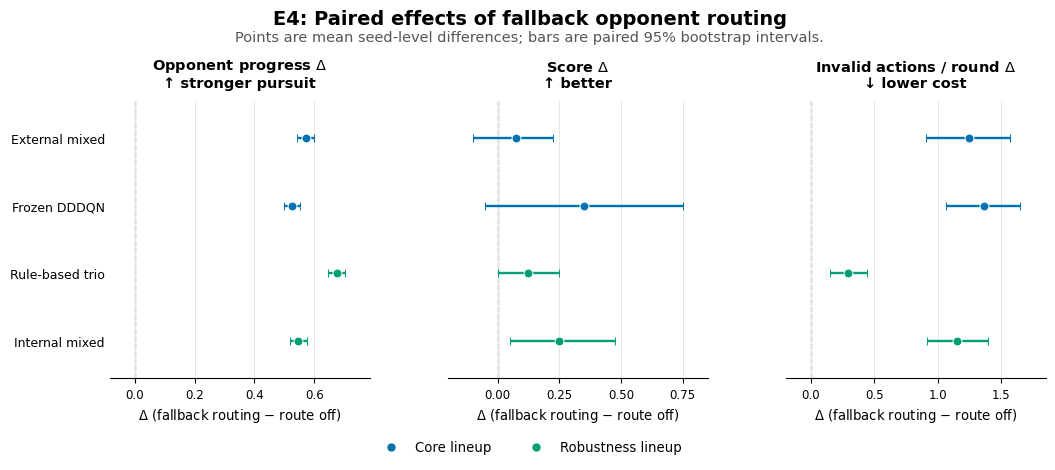

Saved: /Users/spnn/Documents/26SS-ScientificComputing/MachineLearningEssentials/final/MLE_project_bomberman_2026/results/e4_opponent_routing_gate/figure8_e4_paired_opponent_effects.png
Saved: /Users/spnn/Documents/26SS-ScientificComputing/MachineLearningEssentials/final/MLE_project_bomberman_2026/results/e4_opponent_routing_gate/figure8_e4_paired_opponent_effects.pdf


In [2]:
# Reproduce Figure 8 directly from the E4 paired-bootstrap results.
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

project_root = Path('..').resolve()
main_summary_path = project_root / 'results/e4_opponent_routing_gate/summary.json'
extension_summary_path = project_root / 'results/e4_opponent_routing_gate_extension/summary.json'
figure_png = project_root / 'results/e4_opponent_routing_gate/figure8_e4_paired_opponent_effects.png'
figure_pdf = project_root / 'results/e4_opponent_routing_gate/figure8_e4_paired_opponent_effects.pdf'

e4_main = json.loads(main_summary_path.read_text())
e4_extension = json.loads(extension_summary_path.read_text())
paired_bootstrap = e4_main['paired_bootstrap'] + e4_extension['paired_bootstrap']

lineups = (
    ('external_mixed', 'External mixed', '#0072B2', 'Core'),
    ('frozen_dddqn', 'Frozen DDDQN', '#0072B2', 'Core'),
    ('rule3', 'Rule-based trio', '#009E73', 'Robustness'),
    ('internal_mixed', 'Internal mixed', '#009E73', 'Robustness'),
)
metrics = (
    ('opponent_progress', 'Opponent progress $\Delta$', '↑ stronger pursuit'),
    ('score', 'Score $\Delta$', '↑ better'),
    ('invalid', 'Invalid actions / round $\Delta$', '↓ lower cost'),
)
contrast = 'fallback_final-opponent_route_off'

def paired_effect(lineup, metric):
    row = next(
        item for item in paired_bootstrap
        if item['lineup'] == lineup
        and item['contrast'] == contrast
        and item['metric'] == metric
    )
    return row['mean_difference'], row['ci_low'], row['ci_high']

def shared_limits(metric):
    values = [0.0]
    for lineup, *_ in lineups:
        values.extend(paired_effect(lineup, metric))
    span = max(values) - min(values)
    padding = max(span * 0.12, 0.08 if metric != 'invalid' else 0.20)
    return min(values) - padding, max(values) + padding

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5,
    'axes.titlesize': 10.5, 'axes.labelsize': 9.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 9.0,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
fig, axes = plt.subplots(1, 3, figsize=(12, 4.7), constrained_layout=False)
y_positions = list(range(len(lineups)))[::-1]

for ax, (metric, title, direction) in zip(axes, metrics):
    ax.axvline(0, color='#8A8A8A', linewidth=1.0, linestyle='--', zorder=0)
    for y, (lineup, label, color, _) in zip(y_positions, lineups):
        estimate, low, high = paired_effect(lineup, metric)
        ax.errorbar(
            estimate, y,
            xerr=[[estimate - low], [high - estimate]],
            fmt='o', markersize=6.4,
            markerfacecolor=color, markeredgecolor='white', markeredgewidth=0.7,
            ecolor=color, elinewidth=1.7, capsize=3.0, capthick=1.2, zorder=3,
        )
    ax.set_xlim(*shared_limits(metric))
    ax.set_ylim(-0.55, len(lineups) - 0.45)
    ax.set_yticks(y_positions)
    if ax is axes[0]:
        ax.set_yticklabels([item[1] for item in lineups])
    else:
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7, zorder=0)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.set_xlabel(r'$\Delta$ (fallback routing $-$ route off)')
    ax.set_title(f'{title}\n{direction}', pad=10, fontweight='semibold')

legend_handles = [
    Line2D([0], [0], marker='o', color=color, label=label, linestyle='none',
           markerfacecolor=color, markeredgecolor='white', markersize=7)
    for label, color in (('Core lineup', '#0072B2'), ('Robustness lineup', '#009E73'))
]
fig.legend(handles=legend_handles, loc='lower center', ncol=2, frameon=False,
           bbox_to_anchor=(0.55, 0.012), columnspacing=2.4)
fig.suptitle('E4: Paired effects of fallback opponent routing',
             x=0.55, y=0.985, fontsize=14, fontweight='bold')
fig.text(0.55, 0.940,
         'Points are mean seed-level differences; bars are paired 95% bootstrap intervals.',
         ha='center', va='top', fontsize=10.5, color='#555555')
fig.subplots_adjust(left=0.20, right=0.98, top=0.79, bottom=0.20, wspace=0.30)

figure_png.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_png, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(figure_pdf, bbox_inches='tight', facecolor='white')
plt.show()

print(f'Saved: {figure_png}')
print(f'Saved: {figure_pdf}')
